# Hausa Sentiment Classification — Step 1: Data & EDA

**Project type:** Text Classification for an African Language (AfriSenti Hausa)

**Goal of this notebook**
1. Download the official AfriSenti Hausa train / dev / test splits
2. Inspect size, labels, text length, emoji, leakage
3. Apply light preprocessing
4. Save clean CSVs for later training notebooks

Run in **Google Colab**. CPU is enough for this notebook.


## 0. Setup


In [2]:
# Colab: install only what we need for EDA
!pip -q install pandas numpy matplotlib seaborn scikit-learn

import os, re, unicodedata, json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project folders (works in Colab and locally)
ROOT = Path("/content/hausa-sentiment") if Path("/content").exists() else Path(".")
for sub in ["data/raw", "data/processed", "models", "results", "notebooks"]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)

print("ROOT =", ROOT.resolve())


ROOT = C:\Users\hp\Downloads\hausa-sentiment-v2\hausa-sentiment-app\notebooks


## 1. Download official AfriSenti Hausa splits

Source: [afrisenti-semeval/afrisent-semeval-2023](https://github.com/afrisenti-semeval/afrisent-semeval-2023)  
Licence: research use as specified by the AfriSenti authors (Muhammad et al., 2023).


In [3]:
import urllib.request

BASE = "https://raw.githubusercontent.com/afrisenti-semeval/afrisent-semeval-2023/main/data/hau"
RAW = ROOT / "data" / "raw"

for name in ["train.tsv", "dev.tsv", "test.tsv"]:
    url = f"{BASE}/{name}"
    dest = RAW / name
    print(f"Downloading {name} ...")
    urllib.request.urlretrieve(url, dest)
    print("  ->", dest, "bytes:", dest.stat().st_size)

# Peek
for name in ["train.tsv", "dev.tsv", "test.tsv"]:
    df = pd.read_csv(RAW / name, sep="\t")
    print(name, "shape", df.shape, "columns", list(df.columns))
    print(df.head(2))
    print()


  -> data\raw\train.tsv bytes: 1344290
  -> data\raw\dev.tsv bytes: 264727
  -> data\raw\test.tsv bytes: 408260
train.tsv shape (14172, 2) columns ['tweet', 'label']
                                               tweet     label
0  @user Da kudin da Arewa babu wani abin azo aga...  negative
1  @user Kaga wani Adu ar Banda💔😭 wai a haka Shi ...  negative

dev.tsv shape (2677, 2) columns ['tweet', 'label']
                                               tweet     label
0  @user @user Allah ya kai rahmarsa kabarin ta 🤲...  positive
1  @user 🤣🤣🤣 wannan kasa tamu Allah ya kyauta wai...  positive

test.tsv shape (5303, 2) columns ['tweet', 'label']
                                               tweet     label
0  ah su rahama za axha madara sa lemu fah mudai ...  positive
1                             tohh allah shi taimaka  positive



## 2. Load into DataFrames and basic checks


In [4]:
LABELS = ["positive", "neutral", "negative"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}

def load_tsv(path, split):
    df = pd.read_csv(path, sep="\t")
    # official columns: tweet, label
    df = df.rename(columns={"tweet": "text"})
    df["text"] = df["text"].astype(str)
    df["label"] = df["label"].astype(str).str.strip().str.lower()
    # drop unknown labels if any
    df = df[df["label"].isin(LABELS)].copy()
    df["label_id"] = df["label"].map(LABEL2ID)
    df["split"] = split
    return df.reset_index(drop=True)

train = load_tsv(RAW / "train.tsv", "train")
dev   = load_tsv(RAW / "dev.tsv", "dev")
test  = load_tsv(RAW / "test.tsv", "test")

print("Sizes:", {"train": len(train), "dev": len(dev), "test": len(test)})
print("\nLabel distribution (train):")
print(train["label"].value_counts())
print("\nLabel distribution (dev):")
print(dev["label"].value_counts())
print("\nLabel distribution (test):")
print(test["label"].value_counts())


Sizes: {'train': 14172, 'dev': 2677, 'test': 5303}

Label distribution (train):
label
neutral     4912
positive    4687
negative    4573
Name: count, dtype: int64

Label distribution (dev):
label
neutral     896
negative    894
positive    887
Name: count, dtype: int64

Label distribution (test):
label
neutral     1789
negative    1759
positive    1755
Name: count, dtype: int64


## 3. Text length and surface statistics


In [5]:
EMOJI_RE = re.compile(
    "[\U0001F300-\U0001F9FF\U00002700-\U000027BF\U0001F600-\U0001F64F"
    "\U0001F680-\U0001F6FF\U00002600-\U000026FF\U0001FA00-\U0001FAFF]+",
    flags=re.UNICODE,
)

def add_stats(df):
    df = df.copy()
    df["n_chars"] = df["text"].str.len()
    df["n_tokens"] = df["text"].str.split().str.len()
    df["n_emoji"] = df["text"].map(lambda s: len(EMOJI_RE.findall(s)))
    df["has_url"] = df["text"].str.contains(r"https?://|www\.", regex=True, na=False)
    df["has_mention"] = df["text"].str.contains(r"@\w+", regex=True, na=False)
    return df

train = add_stats(train)
dev = add_stats(dev)
test = add_stats(test)

for name, df in [("train", train), ("dev", dev), ("test", test)]:
    print(f"=== {name} ===")
    print(df[["n_chars", "n_tokens", "n_emoji"]].describe().round(1))
    print(f"  % with emoji:   {100*df['n_emoji'].gt(0).mean():.1f}")
    print(f"  % with URL:     {100*df['has_url'].mean():.1f}")
    print(f"  % with mention: {100*df['has_mention'].mean():.1f}")
    print()


=== train ===
       n_chars  n_tokens  n_emoji
count  14172.0   14172.0  14172.0
mean      78.1      14.0      1.2
std       55.0       9.7      0.8
min       17.0       4.0      0.0
25%       40.0       7.0      1.0
50%       60.0      11.0      1.0
75%       97.0      17.0      1.0
max      337.0      58.0     29.0
  % with emoji:   98.5
  % with URL:     3.1
  % with mention: 100.0

=== dev ===
       n_chars  n_tokens  n_emoji
count   2677.0    2677.0   2677.0
mean      81.9      14.7      1.2
std       58.8      10.4      0.6
min       18.0       4.0      0.0
25%       40.0       7.0      1.0
50%       62.0      11.0      1.0
75%      103.0      19.0      1.0
max      309.0      57.0     10.0
  % with emoji:   98.8
  % with URL:     2.6
  % with mention: 100.0

=== test ===
       n_chars  n_tokens  n_emoji
count   5303.0    5303.0   5303.0
mean      67.0      12.5      0.0
std       54.4       9.9      0.1
min        8.0       3.0      0.0
25%       30.0       6.0      0.0
50%  

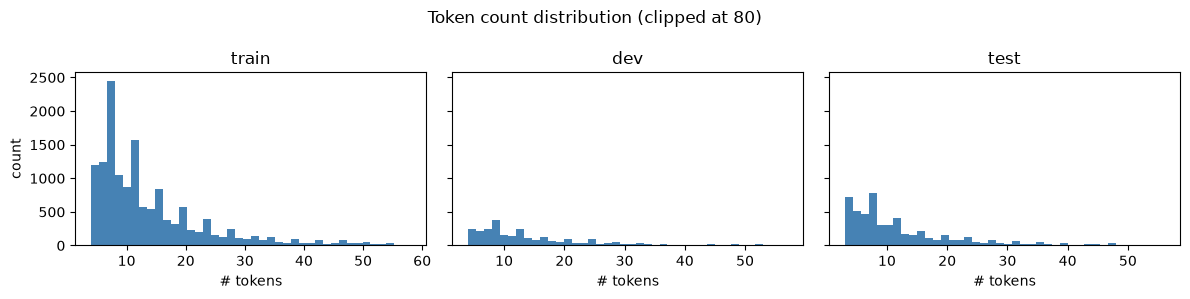

In [6]:
# Plot token-length distributions
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (name, df) in zip(axes, [("train", train), ("dev", dev), ("test", test)]):
    ax.hist(df["n_tokens"].clip(upper=80), bins=40, color="steelblue", edgecolor="none")
    ax.set_title(name)
    ax.set_xlabel("# tokens")
axes[0].set_ylabel("count")
fig.suptitle("Token count distribution (clipped at 80)")
plt.tight_layout()
plt.show()


## 4. Data integrity: train–dev leakage

Exact duplicate texts between train and development inflate validation scores if we tune on raw dev.


In [7]:
train_texts = set(train["text"])
dev_in_train = dev["text"].isin(train_texts)
print(f"Dev rows that also appear in train: {dev_in_train.sum()} / {len(dev)}")

dev_noleak = dev.loc[~dev_in_train].copy()
dev_noleak["split"] = "dev_noleak"
print(f"dev_noleak size: {len(dev_noleak)}")

# Optional: train–test overlap
test_in_train = test["text"].isin(train_texts)
print(f"Test rows that also appear in train: {test_in_train.sum()} / {len(test)}")


Dev rows that also appear in train: 215 / 2677
dev_noleak size: 2462
Test rows that also appear in train: 0 / 5303


## 5. Preprocessing

Light, reversible-style cleaning for classification:
- Unicode NFC
- URLs → `<url>`
- @mentions → `@user`
- collapse whitespace
- keep emoji and Hausa hooked letters


In [8]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
CTRL_RE = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]")

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    t = unicodedata.normalize("NFC", text)
    t = CTRL_RE.sub(" ", t)
    t = URL_RE.sub("<url>", t)
    t = MENTION_RE.sub("@user", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

def text_bow(text: str) -> str:
    """Bag-of-words view: drop placeholders used by classical models."""
    t = clean_text(text)
    t = t.replace("@user", " ").replace("<url>", " ")
    return re.sub(r"\s+", " ", t).strip()

for df in (train, dev, dev_noleak, test):
    df["text_clean"] = df["text"].map(clean_text)
    df["text_bow"] = df["text"].map(text_bow)

print("Example:")
print(" RAW  :", train.loc[0, "text"][:120])
print(" CLEAN:", train.loc[0, "text_clean"][:120])
print(" BOW  :", train.loc[0, "text_bow"][:120])


Example:
 RAW  : @user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikita
 CLEAN: @user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikita
 BOW  : Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana k


## 6. Save processed splits


In [9]:
PROC = ROOT / "data" / "processed"
cols = ["text", "text_clean", "text_bow", "label", "label_id", "split",
        "n_chars", "n_tokens", "n_emoji"]

# recompute stats on original text already present
for name, df in [
    ("afrisenti_hau_train.csv", train),
    ("afrisenti_hau_dev.csv", dev),
    ("afrisenti_hau_dev_noleak.csv", dev_noleak),
    ("afrisenti_hau_test.csv", test),
]:
    out = PROC / name
    df[cols].to_csv(out, index=False)
    print(f"Wrote {out}  ({len(df)} rows)")

# small summary JSON for the report later
summary = {
    "dataset": "AfriSenti Hausa (SemEval 2023 Subtask A)",
    "source": "https://github.com/afrisenti-semeval/afrisent-semeval-2023",
    "citation": "Muhammad et al., EMNLP 2023",
    "labels": LABELS,
    "sizes": {
        "train": len(train),
        "dev": len(dev),
        "dev_noleak": len(dev_noleak),
        "test": len(test),
        "dev_leak_rows": int(dev_in_train.sum()),
    },
}
with open(ROOT / "results" / "data_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))


Wrote data\processed\afrisenti_hau_train.csv  (14172 rows)
Wrote data\processed\afrisenti_hau_dev.csv  (2677 rows)
Wrote data\processed\afrisenti_hau_dev_noleak.csv  (2462 rows)
Wrote data\processed\afrisenti_hau_test.csv  (5303 rows)
{
  "dataset": "AfriSenti Hausa (SemEval 2023 Subtask A)",
  "source": "https://github.com/afrisenti-semeval/afrisent-semeval-2023",
  "citation": "Muhammad et al., EMNLP 2023",
  "labels": [
    "positive",
    "neutral",
    "negative"
  ],
  "sizes": {
    "train": 14172,
    "dev": 2677,
    "dev_noleak": 2462,
    "test": 5303,
    "dev_leak_rows": 215
  }
}


## 7. Short EDA conclusions (for the report)

Write these in your own words later; facts from this notebook:

1. **Sizes:** train ≈ 14.2k, dev ≈ 2.7k, test ≈ 5.3k — enough for classical models and for fine-tuning a small transformer.
2. **Labels:** roughly balanced three-way sentiment (positive / neutral / negative).
3. **Leakage:** ~215 dev rows also appear in train → always validate on `dev_noleak` when tuning.
4. **Register:** train/dev still have emoji and social-media style; test is much cleaner (far fewer emoji). Test scores may not fully match live tweet input.
5. **Preprocessing:** NFC + URL/mention normalisation; emoji and hooked letters kept.

**Next notebook (Step 2):** classical baseline + experiments (TF-IDF word / char / word+char × linear classifiers), evaluated on `dev_noleak` and final test.


## 8. Visual summary of the dataset

These figures summarize the dataset already loaded above.

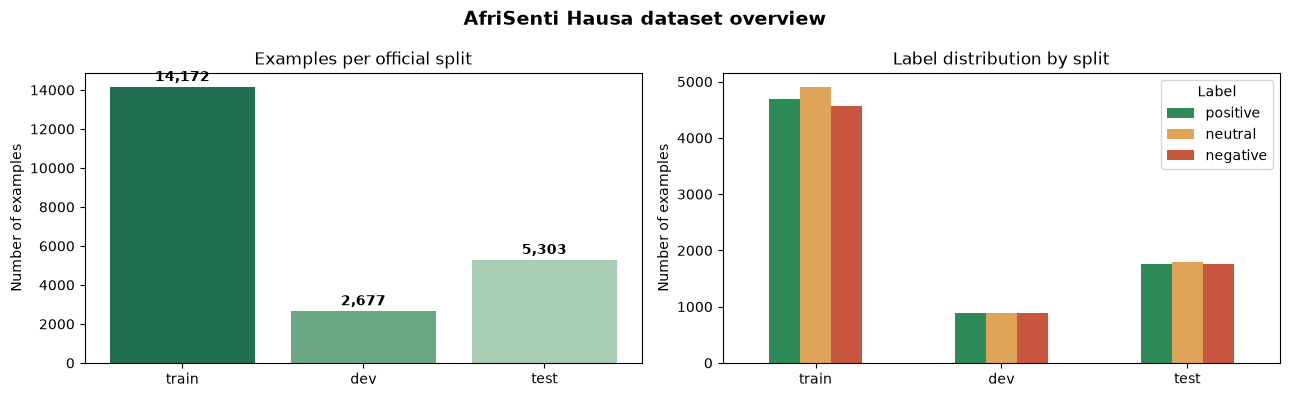

In [10]:
import matplotlib.pyplot as plt

# Visual summary: split sizes and class balance
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

split_frames = [("train", train), ("dev", dev), ("test", test)]
split_names = [name for name, _ in split_frames]
split_sizes = [len(frame) for _, frame in split_frames]
axes[0].bar(split_names, split_sizes, color=["#1f6f50", "#6aa884", "#a7cdb5"])
axes[0].set_title("Examples per official split")
axes[0].set_ylabel("Number of examples")
for index, value in enumerate(split_sizes):
    axes[0].text(index, value + max(split_sizes) * 0.02, f"{value:,}", ha="center", fontweight="bold")

label_counts = pd.DataFrame({name: frame["label"].value_counts().reindex(LABELS) for name, frame in split_frames})
label_counts.T.plot(kind="bar", ax=axes[1], color=["#2e8b57", "#e0a458", "#c8553d"])
axes[1].set_title("Label distribution by split")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of examples")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Label")

fig.suptitle("AfriSenti Hausa dataset overview", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


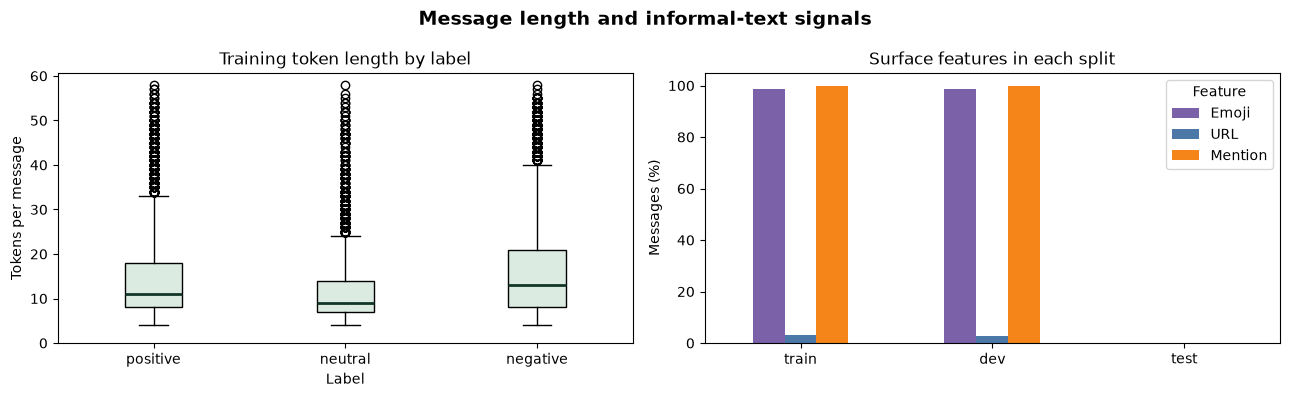

In [11]:
import matplotlib.pyplot as plt

# Visual summary: text length by sentiment and surface-noise prevalence
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

length_by_label = [train.loc[train["label"] == label, "n_tokens"] for label in LABELS]
axes[0].boxplot(length_by_label, patch_artist=True,
                boxprops={"facecolor": "#dcebe1"}, medianprops={"color": "#12372a", "linewidth": 2})
axes[0].set_xticks(range(1, len(LABELS) + 1), LABELS)
axes[0].set_title("Training token length by label")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Tokens per message")
axes[0].set_ylim(bottom=0)

surface_rates = pd.DataFrame({
    "Emoji": [100 * frame["n_emoji"].gt(0).mean() for _, frame in split_frames],
    "URL": [100 * frame["has_url"].mean() for _, frame in split_frames],
    "Mention": [100 * frame["has_mention"].mean() for _, frame in split_frames],
}, index=split_names)
surface_rates.plot(kind="bar", ax=axes[1], color=["#7b61a8", "#4c78a8", "#f58518"])
axes[1].set_title("Surface features in each split")
axes[1].set_xlabel("")
axes[1].set_ylabel("Messages (%)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Feature")

fig.suptitle("Message length and informal-text signals", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
